# Chapter 11: Statistical plots with Seaborn

Matplotlib can draw anything, but you have to tell it every detail: loop over groups, pick colours, add a legend. Seaborn is a library built on top of Matplotlib that does this bookkeeping for you. You hand it a DataFrame and say which columns go where, and it groups, aggregates, colours and labels in one call.

By the end of this chapter you will be able to show distributions, compare groups with box and violin plots, read error bars correctly, colour points by category, split a chart into small panels, draw heatmaps and pair plots, and reshape data into the "tidy" form Seaborn expects. It builds on Chapter 10 (Figure and Axes) and Chapter 8 (grouping, merging and `melt`).

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Seaborn 0.13 calls an old Matplotlib argument inside box plots; hide just that notice
warnings.filterwarnings("ignore", message="vert: bool")

sns.set_theme(style="whitegrid", context="notebook")
print("seaborn version:", sns.__version__)

seaborn version: 0.13.2


`sns.set_theme()` switches on Seaborn's look for every chart that follows, including plain Matplotlib ones: a light grid, softer colours and slightly larger fonts. `style=` picks the background (`"whitegrid"`, `"darkgrid"`, `"white"`, `"ticks"`) and `context=` scales fonts for a `"paper"`, `"notebook"`, `"talk"` or `"poster"`.

We will work mostly with one table: one row per **store per day**, with revenue, number of order lines, Cold Brew cups and the weather in that store's city.

In [2]:
orders = pd.read_csv("data/orders.csv", parse_dates=["timestamp"])
stores = pd.read_csv("data/stores.csv")
weather = pd.read_csv("data/weather.csv", parse_dates=["date"])

orders["revenue"] = orders["qty"] * orders["unit_price"]
orders["date"] = orders["timestamp"].dt.normalize()
orders["cold_brew"] = orders["qty"].where(orders["item"] == "Cold Brew", 0)
orders = orders.merge(stores[["store_id", "city"]], on="store_id")

store_day = (orders.groupby(["date", "store_id", "city"], as_index=False)
             .agg(revenue=("revenue", "sum"), lines=("order_id", "count"),
                  cold_brew=("cold_brew", "sum"))
             .merge(weather, on=["date", "city"]))
store_day["day"] = store_day["date"].dt.day_name().str[:3]
store_day["weekend"] = store_day["date"].dt.day_of_week >= 5
print(store_day.shape)
print(store_day.head(3))

(1464, 10)
        date store_id    city  revenue  lines  cold_brew  temp_c  rain_mm  \
0 2024-01-01       S1    Pune     6650     35          4    23.4      0.0   
1 2024-01-01       S2    Pune     5470     28          6    23.4      0.0   
2 2024-01-01       S3  Mumbai    10980     59          5    24.0      2.6   

   day  weekend  
0  Mon    False  
1  Mon    False  
2  Mon    False  


## 11.1 Why Seaborn, and what "tidy" data means

Seaborn functions follow one pattern: `sns.something(data=df, x="col", y="col", hue="col")`. You name columns, not arrays. For that to work, the data has to be **tidy**:

- each **row** is one observation (here: one store on one day);
- each **column** is one variable (revenue, temperature, city...);
- each **value** sits in its own cell.

`store_day` is tidy. A **wide** table, by contrast, spreads one variable across several columns. Here is weekly revenue in wide form, one column per city, as you would build it with `pivot_table` (see Chapter 8):

In [3]:
weekly = store_day.pivot_table(index=pd.Grouper(key="date", freq="W"),
                               columns="city", values="revenue", aggfunc="sum")
print(weekly.head(3))

city        Bengaluru  Mumbai   Pune
date                                
2024-01-07      33590   71170  85810
2024-01-14      37470   61900  85840
2024-01-21      36440   62800  73060


Wide tables are easy for humans to read, but Seaborn cannot say "colour by city" because city is not a column; it is spread over the column names. `melt` (see Chapter 8) turns wide into tidy:

In [4]:
weekly_long = weekly.reset_index().melt(id_vars="date", var_name="city",
                                        value_name="revenue")
print(weekly_long.head(4))
print(weekly.shape, "->", weekly_long.shape)

        date       city  revenue
0 2024-01-07  Bengaluru    33590
1 2024-01-14  Bengaluru    37470
2 2024-01-21  Bengaluru    36440
3 2024-01-28  Bengaluru    44660
(53, 3) -> (159, 3)


Now `city` is a real column, and one line of Seaborn draws all three cities with a legend. Compare this with the loop we needed in 10.2.

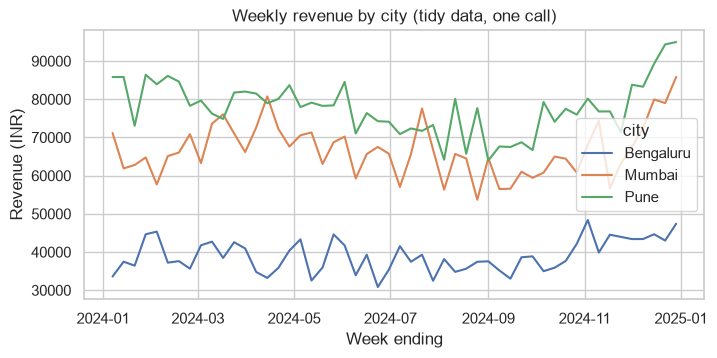

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
full_weeks = weekly_long[weekly_long["date"] < "2025-01-01"]
sns.lineplot(data=full_weeks, x="date", y="revenue", hue="city", ax=ax)
ax.set_title("Weekly revenue by city (tidy data, one call)")
ax.set_xlabel("Week ending")
ax.set_ylabel("Revenue (INR)")
plt.show()

We dropped the partial week that ends in January 2025 (see 9.5). Notice the `ax=ax` argument: most Seaborn functions draw onto a Matplotlib Axes, so everything from Chapter 10 (titles, labels, `subplots`) still applies.

## 11.2 Distributions: histplot, kdeplot and ecdfplot

A **distribution** plot answers "what values are typical, and how spread out are they?" Seaborn has three main ones:

- `histplot`: a histogram, like `ax.hist` but it understands `hue=`;
- `kdeplot`: a smooth curve estimated from the data (a "kernel density estimate"), handy for comparing shapes;
- `ecdfplot`: for each value x, the share of observations at or below x. No bins or smoothing to choose.

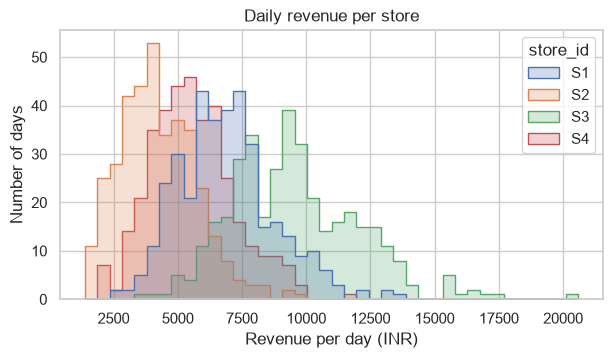

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(data=store_day, x="revenue", hue="store_id", element="step", bins=40, ax=ax)
ax.set_title("Daily revenue per store")
ax.set_xlabel("Revenue per day (INR)")
ax.set_ylabel("Number of days")
plt.show()

Each store has its own hump: S2 (the 24-seat store) sits on the left, S3 in Mumbai on the right. `element="step"` draws outlines instead of filled bars, so overlapping stores stay visible.

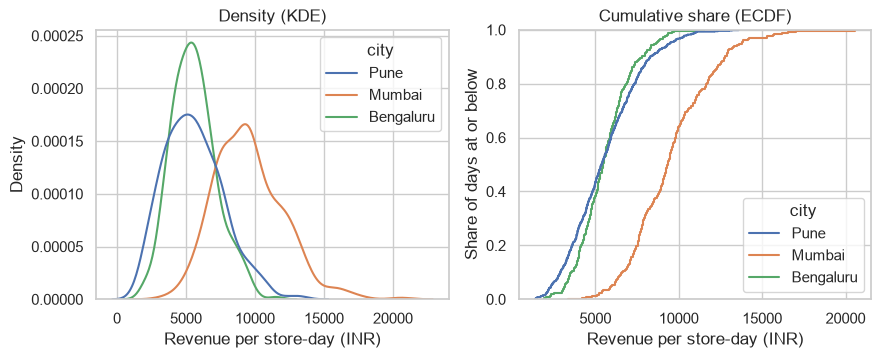

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5))
sns.kdeplot(data=store_day, x="revenue", hue="city", common_norm=False, ax=left)
left.set_title("Density (KDE)")
left.set_xlabel("Revenue per store-day (INR)")
left.set_ylabel("Density")
sns.ecdfplot(data=store_day, x="revenue", hue="city", ax=right)
right.set_title("Cumulative share (ECDF)")
right.set_xlabel("Revenue per store-day (INR)")
right.set_ylabel("Share of days at or below")
plt.show()

`common_norm=False` scales each city's curve on its own, so Pune (two stores, twice as many rows) does not look taller just because it has more data. On the ECDF, read across from 0.5 on the y-axis to find each city's median day.

## 11.3 Comparing groups: box, violin and strip plots

To compare a number across categories, you want to see more than the average. A **box plot** summarises each group in five numbers: the box spans the middle 50% of values (from the 25th to the 75th percentile), the line inside is the median, the whiskers reach out to the bulk of the remaining data, and dots beyond them are outliers.

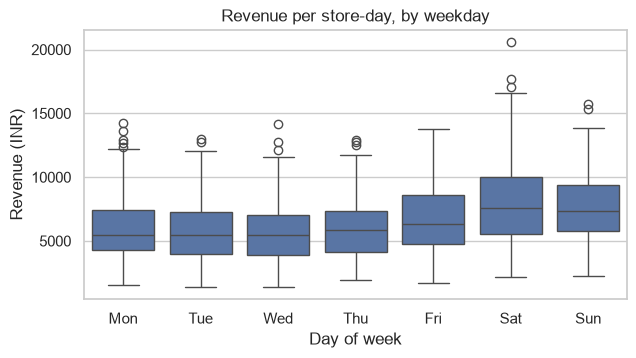

In [8]:
day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(data=store_day, x="day", y="revenue", order=day_order, ax=ax)
ax.set_title("Revenue per store-day, by weekday")
ax.set_xlabel("Day of week")
ax.set_ylabel("Revenue (INR)")
plt.show()

Saturday and Sunday boxes sit higher than the weekday boxes. `order=` fixes the category order; without it, Seaborn uses the order in which values first appear.

A **violin plot** shows the full shape of each group (a KDE mirrored on both sides), and a **strip plot** shows every single point. Points are honest but get crowded; violins are smooth but can hide small samples. Putting them side by side shows the trade-off.

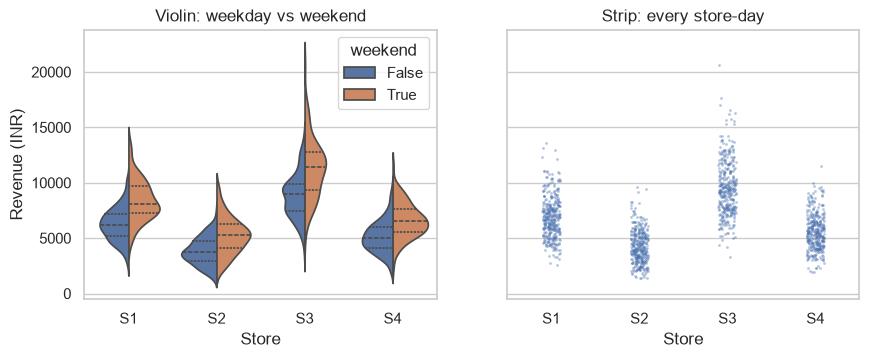

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
sns.violinplot(data=store_day, x="store_id", y="revenue", hue="weekend",
               split=True, inner="quart", ax=left)
left.set_title("Violin: weekday vs weekend")
left.set_xlabel("Store")
left.set_ylabel("Revenue (INR)")
sns.stripplot(data=store_day, x="store_id", y="revenue", size=2, alpha=0.4, ax=right)
right.set_title("Strip: every store-day")
right.set_xlabel("Store")
plt.show()

`split=True` puts weekdays on one half of each violin and weekends on the other, and `inner="quart"` draws the quartiles as dashed lines. In every store the weekend half is shifted upwards.

## 11.4 Averages with error bars: barplot and countplot

`sns.barplot` does not plot your raw values. It **groups and averages** them (the mean by default) and draws a black line on each bar, the **error bar**. What the error bar means depends on the `errorbar=` argument, and readers often get this wrong:

| `errorbar=` | The line shows | Answers |
|---|---|---|
| `("ci", 95)` (default) | 95% confidence interval of the mean | "How precisely do we know the average?" |
| `"sd"` | one standard deviation either side of the mean | "How much do single days vary?" |
| `None` | nothing | |

The confidence interval is computed by **bootstrapping**: Seaborn resamples the data many times and looks at how much the mean moves. Pass `seed=` so the result is the same every run.

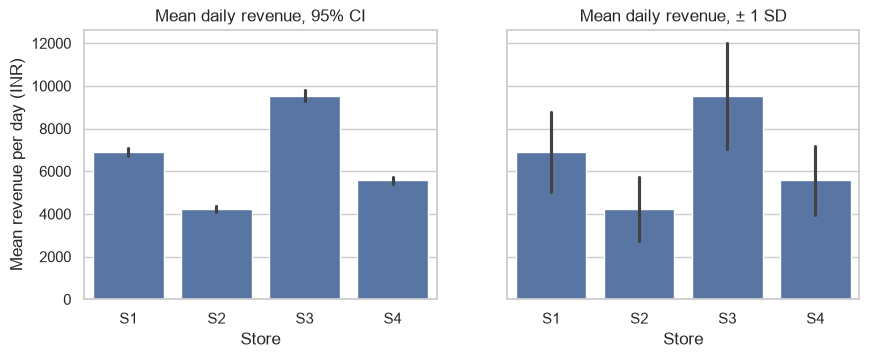

In [10]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
sns.barplot(data=store_day, x="store_id", y="revenue", errorbar=("ci", 95), seed=0, ax=left)
left.set_title("Mean daily revenue, 95% CI")
left.set_xlabel("Store")
left.set_ylabel("Mean revenue per day (INR)")
sns.barplot(data=store_day, x="store_id", y="revenue", errorbar="sd", ax=right)
right.set_title("Mean daily revenue, ± 1 SD")
right.set_xlabel("Store")
plt.show()

The bars are identical; only the lines differ. With 366 days per store we know each **average** very precisely, so the confidence intervals are tiny. Individual **days**, however, vary a lot, so the standard-deviation lines are long. Let's check the numbers behind the bars:

In [11]:
print(store_day.groupby("store_id")["revenue"].agg(["mean", "std", "count"]).round(0))

            mean     std  count
store_id                       
S1        6886.0  1869.0    366
S2        4230.0  1487.0    366
S3        9543.0  2485.0    366
S4        5570.0  1616.0    366


When you just want to **count** rows per category, use `countplot`. It needs only an `x` (or `y`) column.

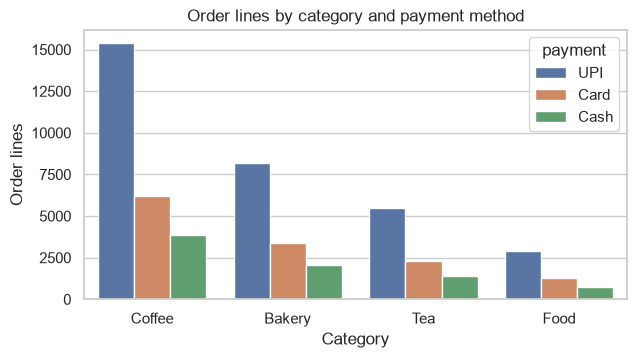

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.countplot(data=orders, x="category", hue="payment",
              order=["Coffee", "Bakery", "Tea", "Food"], ax=ax)
ax.set_title("Order lines by category and payment method")
ax.set_xlabel("Category")
ax.set_ylabel("Order lines")
plt.show()

UPI is the most common payment in every category, followed by card and then cash.

## 11.5 Relationships: scatterplot and lineplot

`scatterplot` and `lineplot` show how one number relates to another. Their power is in three extra arguments that map more columns onto the same chart:

- `hue=`: colour;
- `size=`: marker size (or line width);
- `style=`: marker shape (or dash pattern).

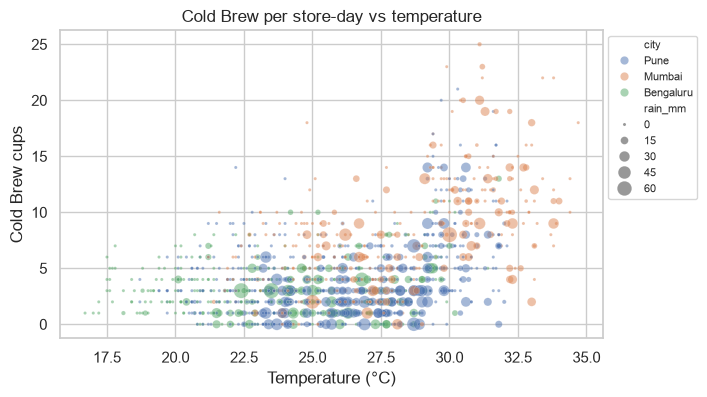

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=store_day, x="temp_c", y="cold_brew", hue="city",
                size="rain_mm", sizes=(5, 120), alpha=0.5, ax=ax)
ax.set_title("Cold Brew per store-day vs temperature")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Cold Brew cups")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.show()

The cloud kinks upwards around 29 °C: hot days sell far more Cold Brew. Bigger dots are rainy days; they cluster at moderate temperatures, because the monsoon is not the hottest season.

`lineplot` has a special talent: if several rows share the same x value, it **averages** them and draws a shaded band for the 95% confidence interval, just like `barplot`. Here x is the month, and each month has about 30 days per store.

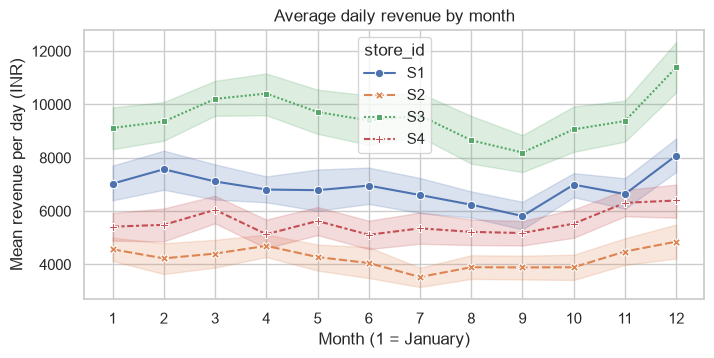

In [14]:
store_day["month"] = store_day["date"].dt.month

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.lineplot(data=store_day, x="month", y="revenue", hue="store_id",
             style="store_id", markers=True, seed=0, ax=ax)
ax.set_title("Average daily revenue by month")
ax.set_xlabel("Month (1 = January)")
ax.set_ylabel("Mean revenue per day (INR)")
ax.set_xticks(range(1, 13))
plt.show()

All four stores dip in the monsoon months and peak in December. `style=` gives each store its own dash pattern and marker as well as its own colour, which helps readers with colour-blindness and readers of black-and-white printouts.

## 11.6 Small multiples: relplot, catplot and displot

A chart with four colours on top of each other can get busy. **Faceting** draws the same chart once per group, in a grid of small panels with shared axes. Seaborn has three "figure-level" functions for this, one per family:

| Function | Family | `kind=` options |
|---|---|---|
| `sns.relplot` | relationships | `"scatter"`, `"line"` |
| `sns.catplot` | categories | `"box"`, `"violin"`, `"strip"`, `"bar"`, `"count"`, ... |
| `sns.displot` | distributions | `"hist"`, `"kde"`, `"ecdf"` |

Use `col=` and `row=` to choose which columns split the panels. These functions create their own figure, so they do **not** take `ax=`. Size each panel with `height=` and `aspect=` (width = height x aspect), and label through the returned object `g`.

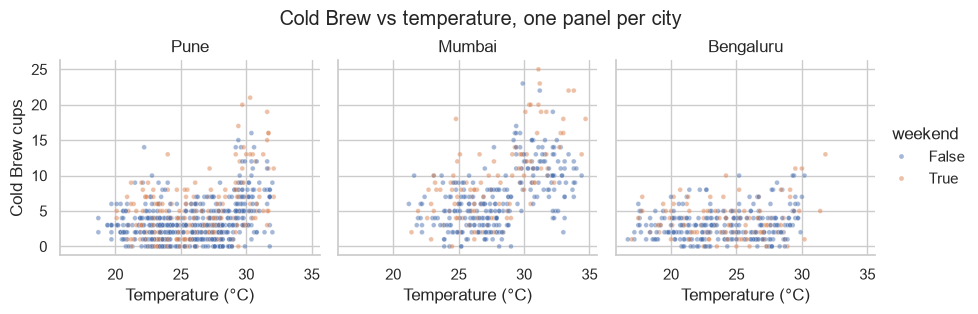

In [15]:
g = sns.relplot(data=store_day, x="temp_c", y="cold_brew", col="city",
                hue="weekend", height=3, aspect=1, alpha=0.5, s=12)
g.set_axis_labels("Temperature (°C)", "Cold Brew cups")
g.set_titles("{col_name}")
g.figure.suptitle("Cold Brew vs temperature, one panel per city", y=1.04)
plt.show()

The same jump above 29 °C appears in every city, and Mumbai has the most hot days. `{col_name}` in `set_titles` is replaced by each panel's value.

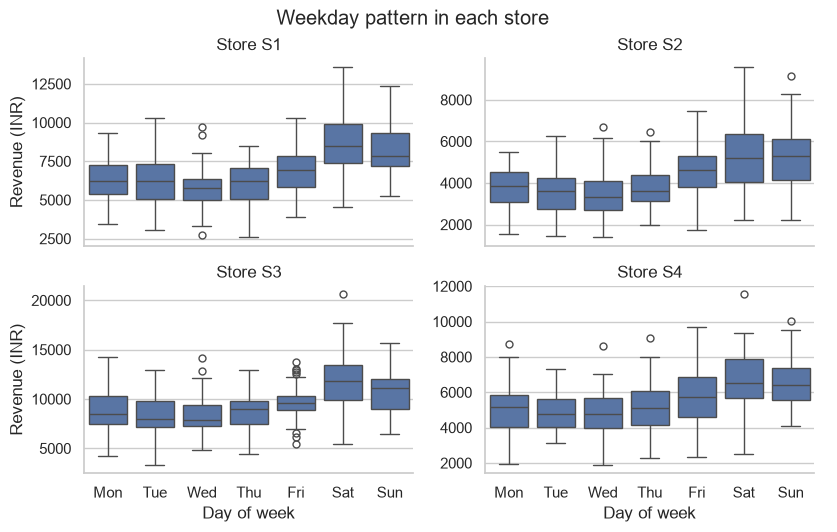

In [16]:
g = sns.catplot(data=store_day, x="day", y="revenue", col="store_id", col_wrap=2,
                kind="box", order=day_order, height=2.6, aspect=1.6, sharey=False)
g.set_axis_labels("Day of week", "Revenue (INR)")
g.set_titles("Store {col_name}")
g.figure.suptitle("Weekday pattern in each store", y=1.02)
plt.show()

`col_wrap=2` wraps four panels into a 2x2 grid. We set `sharey=False` so each store uses its own scale: here we care about each store's weekly **pattern**, not about comparing their sizes. `displot` works the same way for histograms and KDEs, for example `sns.displot(data=store_day, x="revenue", col="city")`.

## 11.7 Heatmaps and pair plots

A **heatmap** colours the cells of a 2-D table, so it suits anything you can make with `pivot_table` (see Chapter 8). This is one place where Seaborn wants **wide** data: rows and columns of the table become rows and columns of the picture.

When is each store busiest? Count order lines by hour and weekday:

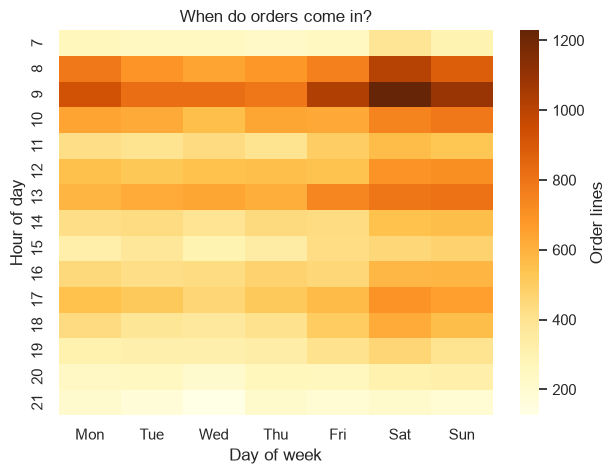

In [17]:
orders["hour"] = orders["timestamp"].dt.hour
orders["day"] = orders["timestamp"].dt.day_name().str[:3]
busy = orders.pivot_table(index="hour", columns="day", values="order_id",
                          aggfunc="count")[day_order]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(busy, cmap="YlOrBr", cbar_kws={"label": "Order lines"}, ax=ax)
ax.set_title("When do orders come in?")
ax.set_xlabel("Day of week")
ax.set_ylabel("Hour of day")
plt.show()

The darkest band is the 9 o'clock rush, with a second, fainter band at lunchtime, and both are strongest at the weekend.

The most common heatmap of all is a **correlation matrix**: the correlation coefficient (from -1 to +1) between every pair of numeric columns. `annot=True` writes the numbers in the cells, and `center=0` with a diverging colour map makes positive and negative correlations different colours.

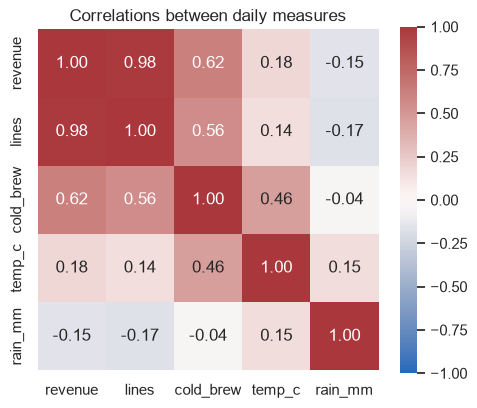

In [18]:
corr = store_day[["revenue", "lines", "cold_brew", "temp_c", "rain_mm"]].corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, ax=ax)
ax.set_title("Correlations between daily measures")
plt.show()

Revenue and order lines are almost perfectly correlated (0.98), which is no surprise. Cold Brew correlates with temperature (0.46), and rain has a weak negative link with revenue (-0.15). Chapter 12 shows how to test whether such a correlation could be chance.

A **pair plot** draws a scatter plot for every pair of columns, with each column's distribution on the diagonal. It is a great first look at a new dataset, but it draws many panels, so use a few columns and a sample of rows.

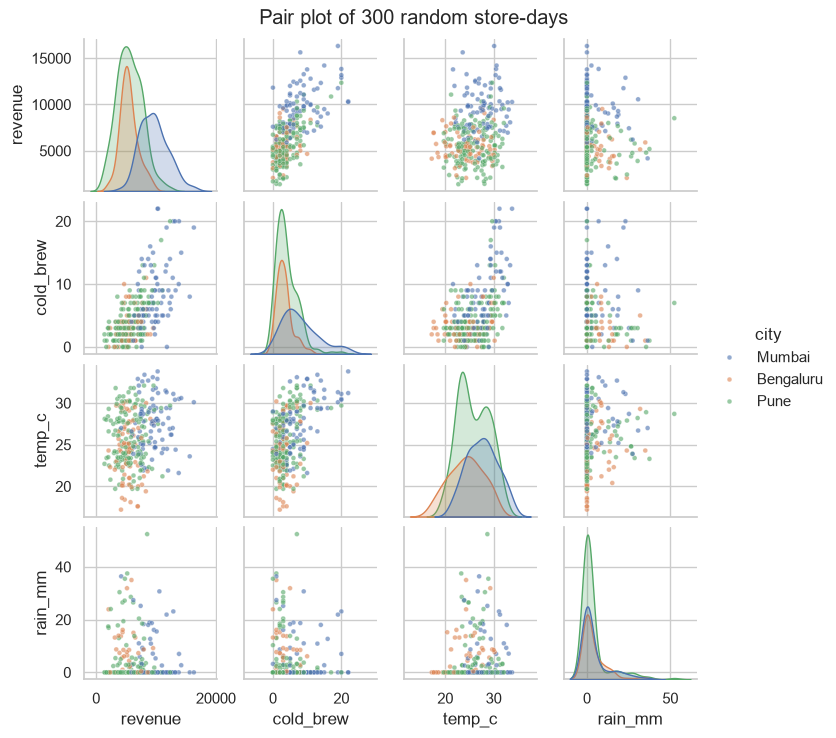

In [19]:
sample = store_day.sample(300, random_state=0)
g = sns.pairplot(sample, vars=["revenue", "cold_brew", "temp_c", "rain_mm"],
                 hue="city", height=1.8, plot_kws={"s": 12, "alpha": 0.6})
g.figure.suptitle("Pair plot of 300 random store-days", y=1.02)
plt.show()

Each axis is labelled with its column name. Look along the `cold_brew` row: the bend against `temp_c` stands out, while the panels against `rain_mm` are squashed to the left because most days have no rain at all.

## 11.8 Common mistakes

| Mistake | What happens | Fix |
|---|---|---|
| Passing a wide table with `hue=` | `ValueError`: the column you named does not exist | `melt` it into tidy form first (see Chapter 8) |
| Reading barplot error bars as the spread of the data | You think single days vary very little | The default is a confidence interval of the mean; use `errorbar="sd"` for spread |
| Passing `ax=` to `relplot`, `catplot` or `displot` | Warning, and the figure is drawn elsewhere | Use axes-level functions (`scatterplot`, `boxplot`...) with `ax=`, or label via `g.set_axis_labels` |
| Unordered categories | Days of the week in random order | `order=["Mon", ..., "Sun"]` |
| `pairplot` on a big table | Very slow, huge output | Pick a few `vars=` and `df.sample(...)` |
| Comparing groups of different sizes with `kdeplot` | The bigger group's curve looks taller | `common_norm=False` |

## 11.9 Cheat sheet

| Task | Code |
|---|---|
| Seaborn look for all plots | `sns.set_theme(style="whitegrid")` |
| Histogram by group | `sns.histplot(data=df, x="col", hue="grp", ax=ax)` |
| Smooth density / ECDF | `sns.kdeplot(...)`, `sns.ecdfplot(...)` |
| Box / violin / strip | `sns.boxplot(data=df, x="grp", y="col", order=[...])` |
| Mean with error bars | `sns.barplot(data=df, x="grp", y="col", errorbar=("ci", 95), seed=0)` |
| Count rows per category | `sns.countplot(data=df, x="grp", hue="other")` |
| Scatter with colour, size, shape | `sns.scatterplot(data=df, x=, y=, hue=, size=, style=)` |
| Mean line with CI band | `sns.lineplot(data=df, x="month", y="col", hue="grp")` |
| Panels by column value | `sns.relplot(..., col="city")`, `sns.catplot(..., kind="box", col=)` |
| Label a figure-level plot | `g.set_axis_labels("x", "y")`, `g.set_titles("{col_name}")` |
| Heatmap of a pivot table | `sns.heatmap(pivot, cmap="YlOrBr")` |
| Correlation heatmap | `sns.heatmap(df.corr(), annot=True, center=0, cmap="vlag")` |
| All pairs at once | `sns.pairplot(df.sample(300), vars=[...], hue="grp")` |
| Wide to tidy | `wide.reset_index().melt(id_vars="date", var_name="city")` |

## 11.10 Exercises

**1.** Using `weather`, draw a box plot of daily temperature for each city, with the cities sorted from coolest to warmest median. Label the chart.

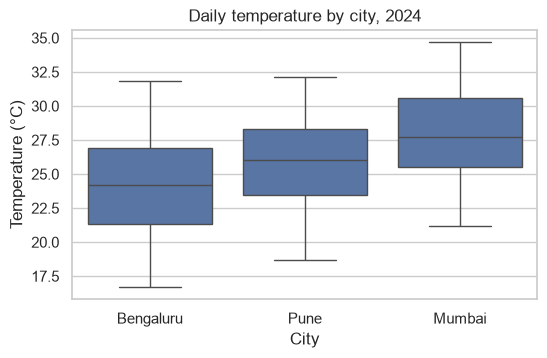

In [20]:
# Solution
city_order = weather.groupby("city")["temp_c"].median().sort_values().index
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.boxplot(data=weather, x="city", y="temp_c", order=city_order, ax=ax)
ax.set_title("Daily temperature by city, 2024")
ax.set_xlabel("City")
ax.set_ylabel("Temperature (°C)")
plt.show()

**2.** Use `barplot` to show the mean `rain_mm` per month for each city (use `weather`, add a `month` column first). Turn the error bars off.

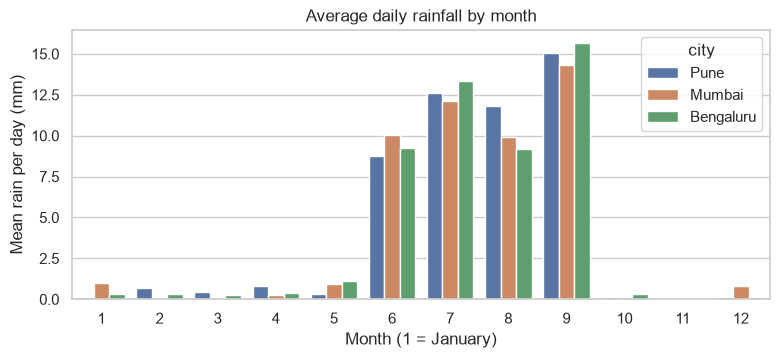

In [21]:
# Solution
w = weather.assign(month=weather["date"].dt.month)
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(data=w, x="month", y="rain_mm", hue="city", errorbar=None, ax=ax)
ax.set_title("Average daily rainfall by month")
ax.set_xlabel("Month (1 = January)")
ax.set_ylabel("Mean rain per day (mm)")
plt.show()

**3.** Make a heatmap of total **revenue** (in thousand INR) by `store_id` (rows) and month (columns), with the values written in each cell as whole numbers.

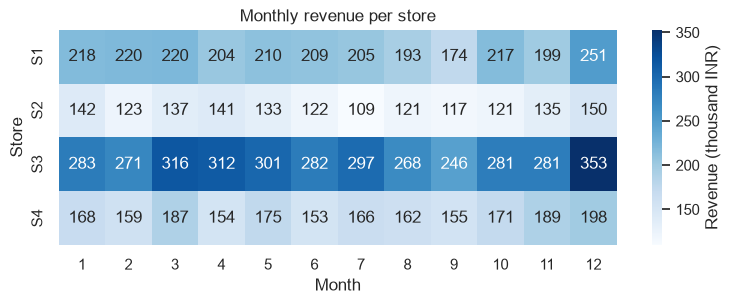

In [22]:
# Solution
rev = store_day.pivot_table(index="store_id", columns="month",
                            values="revenue", aggfunc="sum") / 1000
fig, ax = plt.subplots(figsize=(9, 2.8))
sns.heatmap(rev, annot=True, fmt=".0f", cmap="Blues",
            cbar_kws={"label": "Revenue (thousand INR)"}, ax=ax)
ax.set_title("Monthly revenue per store")
ax.set_xlabel("Month")
ax.set_ylabel("Store")
plt.show()

**4.** Using `weekly` (the wide table from 11.1), check which shape Seaborn needs: make the tidy version yourself and assert that it has exactly three times as many rows as the wide one.

In [23]:
# Solution
tidy = weekly.reset_index().melt(id_vars="date", var_name="city", value_name="revenue")
assert len(tidy) == 3 * len(weekly)
print(tidy["city"].value_counts())

city
Bengaluru    53
Mumbai       53
Pune         53
Name: count, dtype: int64
